In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from altmin import fit_altmin
from skimage.metrics import peak_signal_noise_ratio as psnr
from functools import partial

## Processing Data

In [2]:
#with np.load('img_utils/plane_data_new.npz') as data:
with np.load('img_utils/orig_mouse_data.npz') as data:

    data = data['arr_0']


In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

In [5]:
print(x, y, frames)

70 100 90


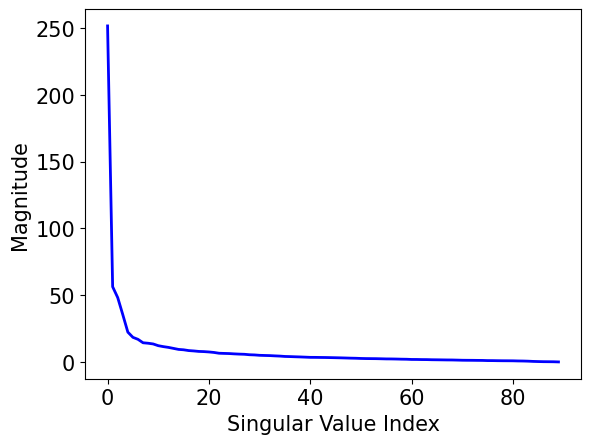

In [6]:
import matplotlib.pyplot as plt
s = np.linalg.svd(vec_data_norm)[1]
plt.plot(s, linewidth=2, color='blue')
#plt.yscale('log')
plt.xlabel(r'Singular Value Index', fontsize=15)
plt.ylabel('Magnitude', fontsize=15)
plt.tick_params(axis='both', which='major', labelsize=15)
# plt.legend(fontsize=15)
#plt.savefig('ossi_svals.png', dpi=300, bbox_inches='tight')

In [7]:
Xs = []

ell = 2 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [8]:
def spectral_init(Ys, frac_observed):
    """
    Performing spectral initialization for missing data case.
    """

    T = len(Ys)
    ell = Ys[0].shape[1]
    
    Xs_init = []

    for t in range(T):
        temp = []
        for i in range(ell):
            spect_mat = np.expand_dims( (1 / frac_observed)*Ys[t][:, i], axis=1 )
            temp.append(np.expand_dims( np.linalg.svd( spect_mat )[0][:, 0], axis=1 ))

        Xs_init.append(np.concatenate(temp, axis=1))
        
    return Xs_init

In [9]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Driver Code

In [10]:
FRAC_OBSERVED = 0.6
SIGMA = 0.01

NTRIALS = 1
NITERS = 250
RANK = 5

# For AltMin
TOL = 1e-3
N_INNER_ITERS = 20

In [11]:
psnr_k_altmin = np.zeros((NTRIALS, ))
psnr_twok_altmin = np.zeros((NTRIALS, ))

ssim_k_altmin = np.zeros((NTRIALS, ))
ssim_twok_altmin = np.zeros((NTRIALS,))

rmse_k_altmin = np.zeros((NTRIALS, ))
rmse_twok_altmin = np.zeros((NTRIALS,))

k_altmin_weight = []
twok_altmin_weight = []

for trial in range( NTRIALS ):
    print('Trial Number: ', trial)

    # Generating data
    forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

    # Generate masked data
    Ys = []

    for i, Xi in enumerate(Xs):
        Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

    # k-AltMin
    Y_concat = np.concatenate(Ys, axis=1)
    X_concat = np.concatenate(Xs, axis=1)

    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
        
    rmse_k_altmin[trial, ] = compute_RMSE(Xs_init, X_concat)
    psnr_k_altmin[trial, ] = compute_PSNR(Xs_init, X_concat)
    ssim_k_altmin[trial, ] = compute_SSIM(Xs_init, X_concat)    
    
    def callback(itr, data):
        cur_rmse = compute_RMSE(data, X_concat)
        cur_psnr = compute_PSNR(data, X_concat)
        cur_ssim = compute_SSIM(data, X_concat)


        if cur_rmse < rmse_k_altmin[trial, ]:
            rmse_k_altmin[trial, ] = cur_rmse
            psnr_k_altmin[trial, ] = cur_psnr
            ssim_k_altmin[trial, ] = cur_ssim
            
    
            k_altmin_weight.append(data)
        
        if itr == NITERS - 1:
            print('(k-AltMin) Iteration:', itr, 'PSNR:', psnr_k_altmin[trial, ],'SSIM:', ssim_k_altmin[trial, ], 'RMSE Error:', rmse_k_altmin[trial, ])  

        return None
    
    L_kaltmin, R_kaltmin = fit_altmin( Xs_init=Xs_init,
                                       rank=RANK,
                                       forward=forward,
                                       transpose=transpose,
                                       Y_concat=Y_concat,
                                       mask=masks,
                                       n_inner_iters=N_INNER_ITERS,
                                       n_outer_iters=NITERS,
                                       tol=TOL,
                                       lr=0.0001,
                                       callback=callback,
                                       ell=ell
    )
    
    
    # 2k-AltMin
    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
        
    rmse_twok_altmin[trial, ] = compute_RMSE(Xs_init, X_concat)
    psnr_twok_altmin[trial, ] = compute_PSNR(Xs_init, X_concat)
    ssim_twok_altmin[trial, ] = compute_SSIM(Xs_init, X_concat)    
    
    def callback(itr, data):
        cur_rmse = compute_RMSE(data, X_concat)
        cur_psnr = compute_PSNR(data, X_concat)
        cur_ssim = compute_SSIM(data, X_concat)
    
        if cur_rmse < rmse_twok_altmin[trial, ]:
            rmse_twok_altmin[trial, ] = cur_rmse
            psnr_twok_altmin[trial, ] = cur_psnr
            ssim_twok_altmin[trial, ] = cur_ssim
            twok_altmin_weight.append(data)

        if itr == NITERS - 1:
            print('(2k-AltMin) Iteration:', itr, 'PSNR:', psnr_twok_altmin[trial, ], 'SSIM:', ssim_twok_altmin[trial, ], 'RMSE Error:', rmse_twok_altmin[trial, ])  

        return None
    
    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)

    L_twokaltmin, R_twokaltmin = fit_altmin( Xs_init=Xs_init,
                                       rank=2*RANK,
                                       forward=forward,
                                       transpose=transpose,
                                       Y_concat=Y_concat,
                                       mask=masks,
                                       n_inner_iters=N_INNER_ITERS,
                                       n_outer_iters=NITERS,
                                       tol=TOL,
                                       lr=0.0001,
                                       callback=callback,
                                       ell=ell
    )

Trial Number:  0
(k-AltMin) Iteration: 249 PSNR: 22.207812295298723 SSIM: 0.7046549735943161 RMSE Error: 0.08746803403334692
(2k-AltMin) Iteration: 249 PSNR: 23.248999787876333 SSIM: 0.7249348659244591 RMSE Error: 0.07650161080031878


## Post-Processing Metrics

In [12]:
psnr_k_mean = np.mean(psnr_k_altmin )
psnr_k_std = np.std(psnr_k_altmin )

psnr_twok_mean = np.mean(psnr_twok_altmin )
psnr_twok_std = np.std(psnr_twok_altmin )

print('(k) PSNR:', psnr_k_mean, psnr_k_std)
print('(2k) PSNR:', psnr_twok_mean, psnr_twok_std)

ssim_k_mean = np.mean(ssim_k_altmin )
ssim_k_std = np.std(ssim_k_altmin )

ssim_twok_mean = np.mean(ssim_twok_altmin )
ssim_twok_std = np.std(ssim_twok_altmin )

print('(k) SSIM:', ssim_k_mean, ssim_k_std)
print('(2k) SSIM:', ssim_twok_mean, ssim_twok_std)

rmse_k_mean = np.mean(rmse_k_altmin )
rmse_k_std = np.std(rmse_k_altmin )

rmse_twok_mean = np.mean(rmse_twok_altmin )
rmse_twok_std = np.std(rmse_twok_altmin )

print('(k) RMSE:', rmse_k_mean, rmse_k_std)
print('(2k) RMSE:', rmse_twok_mean, rmse_twok_std)

(k) PSNR: 22.207812295298723 0.0
(2k) PSNR: 23.248999787876333 0.0
(k) SSIM: 0.7046549735943161 0.0
(2k) SSIM: 0.7249348659244591 0.0
(k) RMSE: 0.08746803403334692 0.0
(2k) RMSE: 0.07650161080031878 0.0


## Plotting

In [13]:
import matplotlib.pyplot as plt

In [14]:
Xs_est_kaltmin = L_kaltmin @ R_kaltmin
Xs_est_twokaltmin = L_twokaltmin @ R_twokaltmin

In [19]:
idx = 40



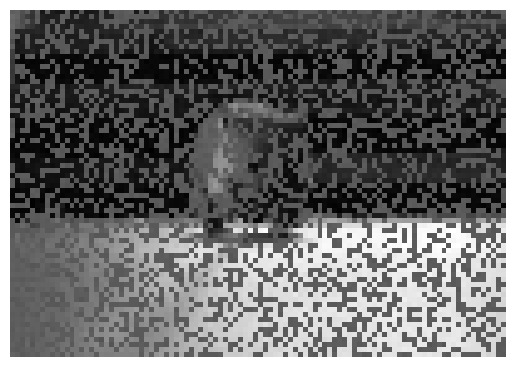

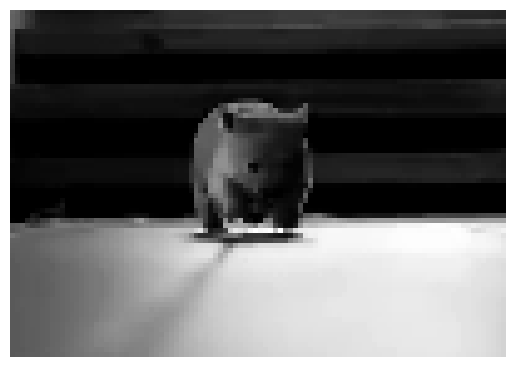

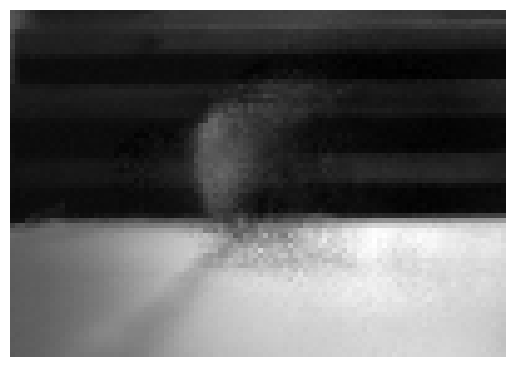

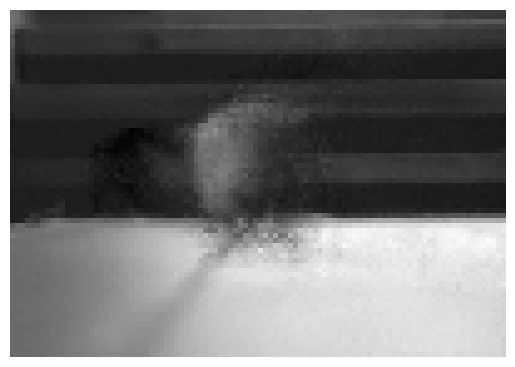

In [24]:

plt.imshow(normalize_np(np.reshape(Y_concat[:, idx], (data.shape[0],data.shape[1]), order='F')), cmap='gray')
plt.axis('off')
plt.savefig(f'mouse_measurement_frame{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(normalize_np(np.reshape(X_concat[:, idx],(data.shape[0],data.shape[1]), order='F')), cmap='gray')
plt.axis('off')
plt.savefig(f'true_mouse_frame{idx}.png', bbox_inches='tight', pad_inches=0)

plt.show()

plt.imshow(normalize_np(np.reshape(Xs_est_kaltmin[:, idx], (data.shape[0],data.shape[1]), order='F')), cmap='gray')
plt.axis('off')
plt.savefig(f'mouse_k_altmin_frame{idx}_r5.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(normalize_np(np.reshape(Xs_est_twokaltmin[:, idx], (data.shape[0],data.shape[1]), order='F')), cmap='gray')
plt.axis('off')
plt.savefig(f'mouse_twok_altmin_frame{idx}_r5.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [21]:
psnr(normalize_np(Xs_est_kaltmin[:, idx]), normalize_np(X_concat[:, idx]))

22.73452003544098

In [22]:
psnr(normalize_np(Xs_est_twokaltmin[:, idx]), normalize_np(X_concat[:, idx]))

20.043898266842387

In [ ]:
for idx in range(twok_altmin_weight[-1].shape[1]):
    print(idx, psnr(normalize_np(twok_altmin_weight[-1][:, idx]), normalize_np(X_concat[:, idx])))

In [ ]:
for idx in range(15):
    plt.imshow(normalize_np(np.reshape(X_concat[:, -idx], (data.shape[0],data.shape[1]), order='F')), cmap='gray')
    plt.axis('off')
    #plt.savefig(f'images/mouse_twok_altmin_frame{idx}.png', bbox_inches='tight', pad_inches=0)
    plt.show()